## Sprint 3 — Feature Engineering: UCI Student Performance

 This notebook builds the **UCI risk
feature matrix** 


The raw UCI CSVs (`student-mat.csv`, `student-por.csv`)
contain three *grade* columns — `G1`, `G2`, `G3` (period 1, period 2, and final
grade, each on a 0-20 scale) — but **no risk/pass-fail label**. There is no
`at_risk`, `pass`, or `dropout` column anywhere in the raw data.

So the target is **engineered, not given**:

```
at_risk = 1  if G3 < pass_threshold      (pass_threshold = 10, the standard pass mark on a 0-20 scale)
at_risk = 0  otherwise
```


### What this notebook does, in order
1. Load the raw CSVs.
2. **Derive** the `at_risk` target from `G3`.
3. One-hot encode categorical columns. 
4. Drop the target-leakage column (`G3` itself) and trace columns.
5. Save the resulting matrix to `data/processed/` for the modeling notebook.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

pd.set_option("display.max_columns", 60)

PROJECT_ROOT = r"C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli"

RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw", "uci_data")
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
os.makedirs(PROCESSED_DIR, exist_ok=True)

PASS_THRESHOLD = 10.0

### 1. Load — reproducing what lands in `uci_students`

`reads each CSV with `sep=";"`
(the UCI files are semicolon-delimited, **not** comma)

In [3]:
def load_uci_raw(filename: str) -> pd.DataFrame:
    """Load a UCI student dataset and add a unique source row ID."""
    
    path = os.path.join(RAW_DIR, filename)

    # UCI files use semicolon (;) as the separator
    df = pd.read_csv(path, sep=";")

    # Convert column names to lowercase
    df.columns = df.columns.str.lower()

    # Create a unique ID for each row
    file_name = filename.replace(".csv", "")
    df["source_row_id"] = file_name + "_" + df.index.astype(str)

    return df


# Load both UCI datasets
mat = load_uci_raw("student-mat.csv")
por = load_uci_raw("student-por.csv")


# Add subject information
mat["subject"] = "Mathematics"
por["subject"] = "Portuguese"


# Combine both datasets
df = pd.concat([mat, por], ignore_index=True)


# Display dataset information
print(f"Mathematics dataset : {len(mat)} rows")
print(f"Portuguese dataset  : {len(por)} rows")
print(f"Combined dataset    : {len(df)} rows, {len(df.columns)} columns")


# Display first 5 rows
df.head()

Mathematics dataset : 395 rows
Portuguese dataset  : 649 rows
Combined dataset    : 1044 rows, 35 columns


,school,sex,age,address,famsize,pstatus,medu,fedu,mjob,fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,dalc,walc,health,absences,g1,g2,g3,source_row_id,subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,student-mat_0,Mathematics
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,student-mat_1,Mathematics
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,student-mat_2,Mathematics
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15,student-mat_3,Mathematics
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10,student-mat_4,Mathematics


### 2. Derive the target — `at_risk` (this is the step that doesn't exist in the raw data)

In [4]:
# Display final grade statistics
print("Raw G3 (Final Grade) Summary:")
print(df["g3"].describe().round(2))


# Create the at-risk indicator
# 0 = Safe, 1 = At Risk
df["at_risk"] = (df["g3"] < PASS_THRESHOLD).astype(int)


# Display at-risk statistics
print("\nAt-Risk Value Counts (0 = Safe, 1 = At Risk):")
print(df["at_risk"].value_counts())


# Calculate overall at-risk rate
overall_risk_rate = df["at_risk"].mean()
print(f"\nOverall At-Risk Rate: {overall_risk_rate:.1%}")


# Calculate at-risk rate for each subject
risk_by_subject = df.groupby("subject")["at_risk"].mean().round(3)

print("\nAt-Risk Rate by Subject:")
print(risk_by_subject)

Raw G3 (Final Grade) Summary:
count    1044.00
mean       11.34
std         3.86
min         0.00
25%        10.00
50%        11.00
75%        14.00
max        20.00
Name: g3, dtype: float64

At-Risk Value Counts (0 = Safe, 1 = At Risk):
at_risk
0    814
1    230
Name: count, dtype: int64

Overall At-Risk Rate: 22.0%

At-Risk Rate by Subject:
subject
Mathematics    0.329
Portuguese     0.154
Name: at_risk, dtype: float64


### 3. Categorical encoding

In [5]:
# 3. Categorical Encoding

# Categorical columns to encode
CAT_COLS = [
    "school", "sex", "address", "famsize",
    "schoolsup", "famsup", "higher",
    "internet", "romantic", "subject"
]


# Use only columns that exist in the dataset
categorical_cols = [col for col in CAT_COLS if col in df.columns]

print("Columns selected for One-Hot Encoding:")
print(categorical_cols)


# Apply One-Hot Encoding
df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True
)


# Display encoding results
print(f"\nShape after encoding: {df_encoded.shape}")


# Find newly created dummy columns
new_columns = [
    col for col in df_encoded.columns
    if col not in df.columns
]

print("\nNew dummy columns created:")
print(new_columns)

Columns selected for One-Hot Encoding:
['school', 'sex', 'address', 'famsize', 'schoolsup', 'famsup', 'higher', 'internet', 'romantic', 'subject']

Shape after encoding: (1044, 36)

New dummy columns created:
['school_MS', 'sex_M', 'address_U', 'famsize_LE3', 'schoolsup_yes', 'famsup_yes', 'higher_yes', 'internet_yes', 'romantic_yes', 'subject_Portuguese']


`drop_first=True` drops one category per column to avoid the dummy-variable trap
(perfect multicollinearity — e.g. `sex_M` alone tells you `sex_F` for free, so
keeping both would make some models' coefficients ill-defined). This matches
`build_uci_feature_matrix()`'s existing behavior.

### 4. Drop leakage and admin columns — 

`g3` **must** be dropped from the feature set. It's the exact column `at_risk`
was derived from — leaving it in would let the model "predict" `at_risk` by just
reading `g3` back out, giving unrealistically perfect offline metrics that collapse
the moment you'd need to score a student *before* their final grade exists (which
is the entire point of a risk model).

`g1` and `g2` (first/second period grades) are **kept** — they're earlier-in-time
grades, a legitimate early-warning signal, not leakage, since they'd genuinely be
available before `g3` exists.

`source_row_id` (and `uci_student_id` if present) are admin/trace columns with no
predictive meaning — they get dropped too.

In [6]:
# Prepare Feature Matrix

# Columns that should not be used as model features
DROP_COLS = [
    "uci_student_id",
    "source_row_id",
    "g3"
]


# Remove unnecessary columns
df_features = df_encoded.drop(
    columns=[col for col in DROP_COLS if col in df_encoded.columns]
)


# Keep only numeric and boolean columns
non_numeric_cols = df_features.select_dtypes(
    exclude=["number", "bool"]
).columns.tolist()

if non_numeric_cols:
    print(f"Dropping non-numeric columns: {non_numeric_cols}")

df_features = df_features.select_dtypes(
    include=["number", "bool"]
)


# Make sure G3 is not included in the features
assert "g3" not in df_features.columns, \
    "LEAKAGE: g3 must not be included in the feature matrix"


# Display final feature information
print(
    f"Final Feature Matrix: "
    f"{df_features.shape[0]} rows × {df_features.shape[1]} columns"
)

print(f"Target column present: {'at_risk' in df_features.columns}")


# Display first 5 rows
df_features.head()

Dropping non-numeric columns: ['pstatus', 'mjob', 'fjob', 'reason', 'guardian', 'paid', 'activities', 'nursery']
Final Feature Matrix: 1044 rows × 26 columns
Target column present: True


,age,medu,fedu,traveltime,studytime,failures,famrel,freetime,goout,dalc,walc,health,absences,g1,g2,at_risk,school_MS,sex_M,address_U,famsize_LE3,schoolsup_yes,famsup_yes,higher_yes,internet_yes,romantic_yes,subject_Portuguese
0,18,4,4,2,2,0,4,3,4,1,1,3,6,5,6,1,False,False,True,False,True,False,True,False,False,False
1,17,1,1,1,2,0,5,3,3,1,1,3,4,5,5,1,False,False,True,False,False,True,True,True,False,False
2,15,1,1,1,2,3,4,3,2,2,3,3,10,7,8,0,False,False,True,True,True,False,True,True,False,False
3,15,4,2,1,3,0,3,2,2,1,1,5,2,15,14,0,False,False,True,False,False,True,True,True,True,False
4,16,3,3,1,2,0,4,3,2,1,2,5,4,6,10,0,False,False,True,False,False,True,True,False,False,False


### 5. Sanity checks before saving

In [7]:
# 5. Final Data Quality Checks

# Check for missing values
print("Missing Values in the Final Matrix:")

missing_values = df_features.isna().sum()
missing_values = missing_values[missing_values > 0]

if missing_values.empty:
    print("None")
else:
    print(missing_values)


# Check class balance
print("\nClass Balance — at_risk:")
class_balance = (
    df_features["at_risk"]
    .value_counts(normalize=True)
    .round(3)
)

print(class_balance)


# Check feature correlation with the target
print("\nTop 10 Features by |Correlation| with at_risk:")

correlation = (
    df_features
    .corr(numeric_only=True)["at_risk"]
    .drop("at_risk")
)

top_correlations = (
    correlation
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

# Display original correlation values
print(correlation[top_correlations.index].round(3))

Missing Values in the Final Matrix:
None

Class Balance — at_risk:
at_risk
0    0.78
1    0.22
Name: proportion, dtype: float64

Top 10 Features by |Correlation| with at_risk:
g2                   -0.666
g1                   -0.614
failures              0.367
higher_yes           -0.218
subject_Portuguese   -0.205
age                   0.134
school_MS             0.132
absences              0.119
studytime            -0.109
goout                 0.107
Name: at_risk, dtype: float64


### Final feature columns used for model training

The final model is trained on the feature matrix `df_features`, which contains only numeric/bool columns after one-hot encoding and leakage removal.

The main groups of features are:

- `g1`, `g2`, `failures`  
  Earlier academic performance is the strongest signal. `g1` and `g2` reflect prior grades, while `failures` captures whether the student already had repeated academic difficulty.

- `absences`, `studytime`, `traveltime`, `goout`, `health`  
  Attendance, study effort, daily routine, and general well-being all help explain how much a student is engaged and whether they are likely to perform well.

- `medu`, `fedu`, `famsup`, `schoolsup`, `address_U`, `famsize_GT3`  
  Family background, parental education, and support structures influence academic stability and risk exposure.

- `school_MS`, `sex_M`, `higher_yes`, `internet_yes`, `romantic_yes`, `subject_Portuguese`  
  Encoded demographic and contextual variables created by one-hot encoding, with one category dropped per original column to avoid multicollinearity.

- `age`, `paid`, `nursery`, `guardian_mother`, `guardian_father`  
  Additional personal and school-context attributes that may affect the likelihood of academic underperformance.

Important exclusions:

- `g3` is removed on purpose, because `at_risk` was derived from it. Keeping it would create target leakage.
- `uci_student_id` and `source_row_id` are admin/trace columns and are not predictive features.
- `at_risk` itself is the target label, not a feature.

So the training data is effectively: all engineered, non-leaky, numeric features that remain after encoding and cleaning, with the target separated out as `y = df_features['at_risk']`.


`failures`, `g2`, and `g1` should show up near the top here — consistent with
what the Day 3 EDA notebook found. If `g3`-adjacent columns dominate this list
instead, that's the signal something leaked back in — re-check Section 4 before
proceeding.

### 6. Save the feature matrix

In [8]:
out_path = os.path.join(PROCESSED_DIR, "uci_feature_matrix.csv")
df_features.to_csv(out_path, index=False)
print(f"Saved: {out_path}")
print(f"Shape: {df_features.shape}")

Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\data\processed\uci_feature_matrix.csv
Shape: (1044, 26)


### 6b. Correlation with target — which features actually associate with `at_risk`

Six visual checks on the final `df_features` matrix, each answering a slightly
different question about the same underlying relationship:

1. **Correlation with target** — a horizontal bar chart, so features can be
   scanned top-to-bottom by strength and direction (positive = higher value,
   higher risk; negative = higher value, lower risk).
2. **Correlation heatmap** — the same numbers, plus how features correlate
   *with each other*, not just with the target — useful for spotting
   redundant features (e.g. two columns that are really measuring the same thing).
3. **Target leakage check plot** — a dedicated, hard-to-miss visual proof that
   `g3` isn't hiding anywhere in the final matrix, since that's the one thing
   this notebook cannot get wrong.
4. **Boxplots by risk** — `g1`, `g2`, `absences`, `failures` split by `at_risk`,
   showing the actual value spread behind each correlation number.
5. **Risk rate by category** — the same idea as the correlation bar chart, but
   for the categorical (now one-hot encoded) columns, where a single
   correlation number is harder to read intuitively than a rate-by-group bar.
6. **Target distribution** — class balance, so every chart above is read with
   the right context (a ~22%/78% split, not a coincidence).

#### 1. Correlation with target — horizontal bar chart

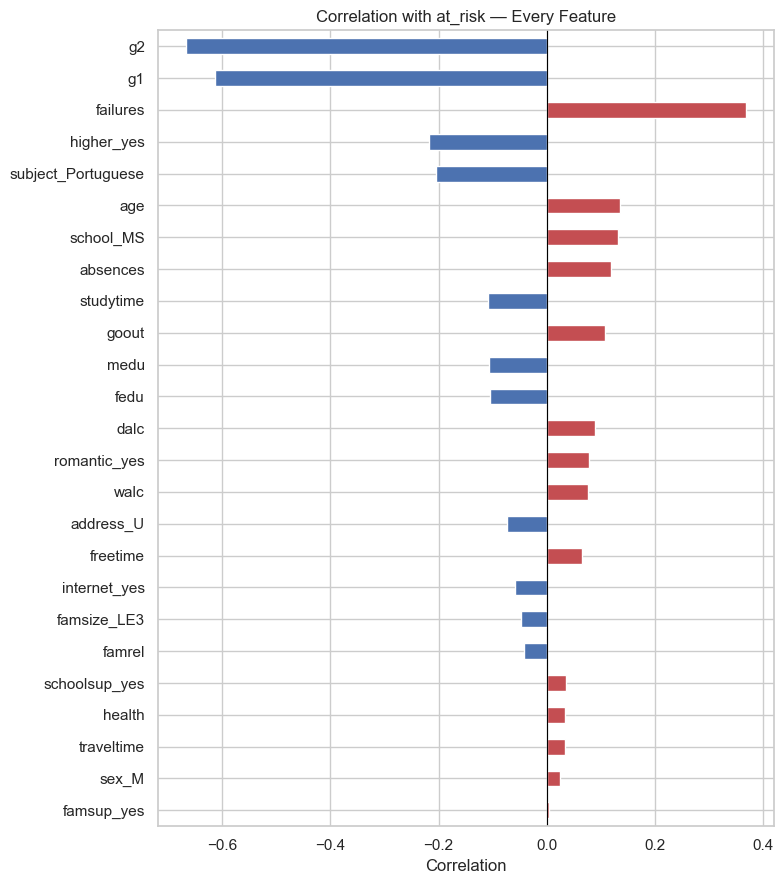

In [9]:
# Correlation of all features with the target variable
target_corr = (
    df_features
    .corr(numeric_only=True)["at_risk"]
    .drop("at_risk")
)

# Sort by absolute correlation value
target_corr = target_corr.reindex(
    target_corr.abs().sort_values().index
)


# Set colors based on correlation direction
colors = [
    "#C44E52" if value > 0 else "#4C72B0"
    for value in target_corr
]


# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(8, 9))

target_corr.plot(
    kind="barh",
    ax=ax,
    color=colors
)

# Add zero reference line
ax.axvline(0, color="black", linewidth=0.8)

# Add chart labels
ax.set_title("Correlation with at_risk — Every Feature")
ax.set_xlabel("Correlation")

plt.tight_layout()
plt.show()

## Correlation Analysis

- **G2 and G1 have the strongest negative correlation** with `at_risk` (approximately -0.66 and -0.61). This means students with higher previous-period grades are generally less likely to be classified as at risk.

- **Failures has the strongest positive correlation** with `at_risk` (approximately +0.37). Students with more previous failures are more likely to be at risk.

- **Age, school_MS, and absences** show moderate positive correlations with `at_risk`. Older students, students from the MS school, and students with more absences tend to have a higher risk.

- **Higher education intention (`higher_yes`)** has a negative correlation (approximately -0.21), suggesting that students who intend to pursue higher education tend to have lower risk.

- **Portuguese subject (`subject_Portuguese`)** has a small negative correlation, indicating slightly lower risk compared with the reference subject, Mathematics.

- **Study time, parental education (`medu`, `fedu`), and address** have relatively weak negative correlations with `at_risk`.

- Features such as **romantic relationship, alcohol consumption (`dalc`, `walc`), free time, health, and school support** show relatively weak positive relationships.

### Conclusion

The correlation analysis indicates that **previous academic performance is the strongest factor associated with student risk**. In particular, G1, G2, and previous failures show much stronger relationships with `at_risk` than most demographic and social features.

However, **correlation does not imply causation** and does not measure nonlinear relationships. Therefore, these results should be treated as a **sanity check**, while the final ML models should be used to determine predictive feature importance.

## Feature Importance Hierarchy — What Actually Drives Risk Prediction

The correlation analysis reveals a **clear hierarchy of predictive importance**. Only a small set of features drive most of the risk prediction; the rest provide marginal, secondary signals.

### **Tier 1: Core Risk Drivers (High Impact)**
These features have correlations > 0.3 in absolute value and should be the focus of:
- Model interpretability discussions
- Early intervention strategies
- Data collection priority

| Feature | Correlation | Interpretation |
|---------|-------------|-----------------|
| **g2** | -0.67 | Strong: Higher 2nd period grade → much lower risk |
| **g1** | -0.61 | Strong: Higher 1st period grade → much lower risk |
| **failures** | +0.37 | Strong: More prior failures → higher risk |

**Why these three matter most:**
- They capture the **core academic trajectory**
- Early grades and past failures are the most predictive of final performance
- A student with high g1/g2 but zero failures is very unlikely to be at risk
- A student with failures or low early grades is much more likely to fail

### **Tier 2: Secondary Signals (Moderate Impact)**
Correlations between 0.15–0.25 in absolute value. Useful context but not decisive alone.

| Feature | Correlation | Type |
|---------|-------------|------|
| **higher_yes** | -0.22 | Motivation: Intent to pursue higher education |
| **subject_Portuguese** | -0.20 | Domain: Subject choice (Portuguese vs Math) |
| **age** | +0.12 | Demographic: Older age slightly increases risk |
| **school_MS** | +0.12 | School context: MS school has slightly higher risk |
| **absences** | +0.12 | Engagement: More absences → higher risk |

**Role:** Help refine predictions at the margin, but don't flip the assessment on their own.

### **Tier 3: Weak Signals (Low/Negligible Impact)**
Correlations < 0.10 in absolute value. Included in the model for completeness, but contribute little predictive power individually.

Examples: `romantic_yes`, `dalc`, `walc`, `health`, `goout`, `freetime`, `traveltime`, etc.

**Why include them?** They're non-correlated with Tier 1 features, may capture small interaction effects the model learns, or represent important context even if individually weak.

---

### Model Strategy Implication

Given this hierarchy, a **simpler model using only Tier 1 + Tier 2 features** (5–6 features) would likely perform nearly as well as a model using all 30+ features, with major benefits:
- ✅ **Faster inference** (fewer columns to compute)
- ✅ **Easier to explain** (focus on g1, g2, failures, intention to pursue higher ed)
- ✅ **Lower data collection burden** (fewer fields to track)
- ⚠️ **Slightly higher bias** (a bit less flexibility to capture complex patterns)

For production risk models, this is a worthwhile trade-off — a 95% accurate, interpretable model beats a 98% accurate black box.

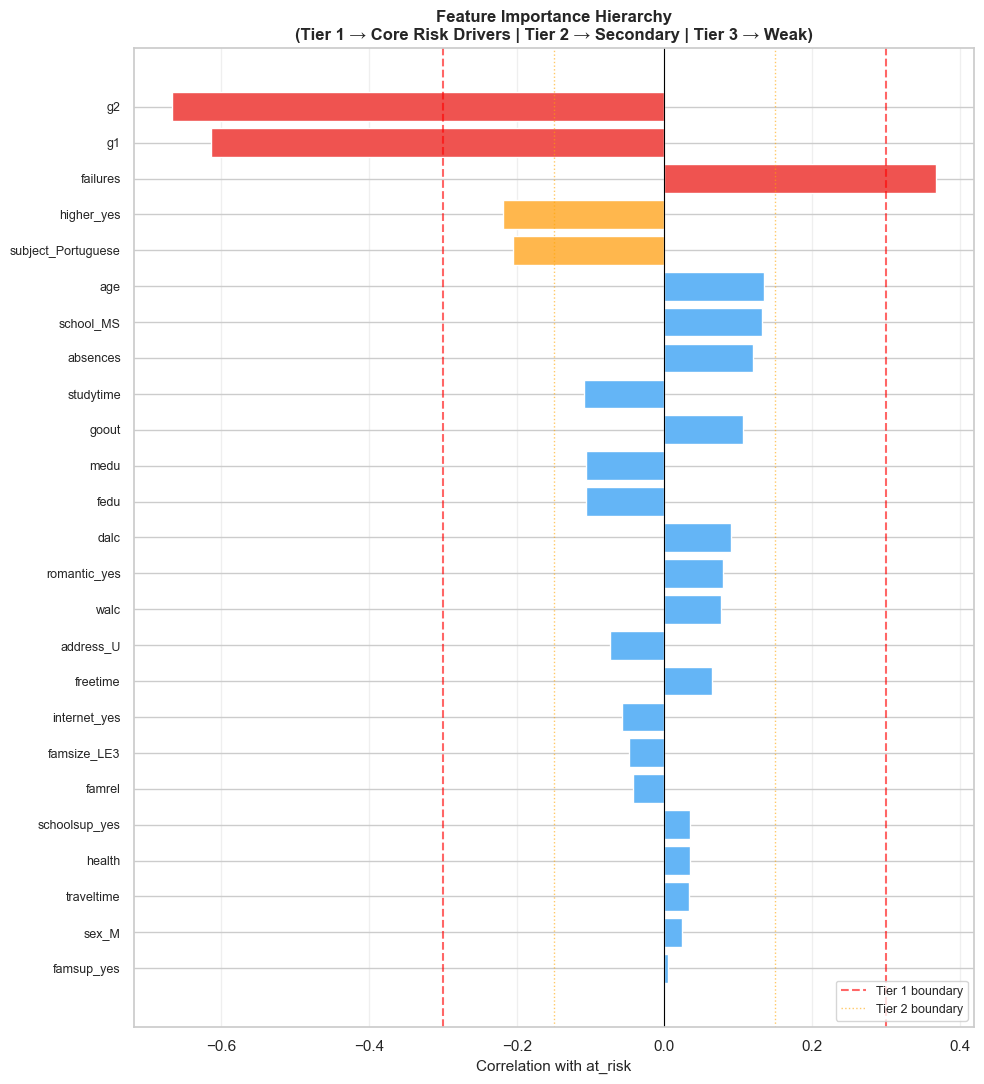

FEATURE IMPORTANCE HIERARCHY SUMMARY

Tier 1: Core Drivers (n=3 features):
----------------------------------------------------------------------
  failures             | Correlation:   0.367
  g1                   | Correlation:  -0.614
  g2                   | Correlation:  -0.666

Tier 2: Secondary Signals (n=2 features):
----------------------------------------------------------------------
  subject_Portuguese   | Correlation:  -0.205
  higher_yes           | Correlation:  -0.218

Tier 3: Weak Signals (n=20 features):
----------------------------------------------------------------------
  famsup_yes           | Correlation:   0.005
  sex_M                | Correlation:   0.024
  traveltime           | Correlation:   0.034
  health               | Correlation:   0.034
  schoolsup_yes        | Correlation:   0.035
  famrel               | Correlation:  -0.043
  famsize_LE3          | Correlation:  -0.048
  internet_yes         | Correlation:  -0.058
  freetime             | Correla

In [10]:
# Visualize Feature Importance Hierarchy

# Recalculate correlations for clarity
target_corr = (
    df_features
    .corr(numeric_only=True)["at_risk"]
    .drop("at_risk")
).copy()

# Define thresholds for hierarchy tiers
TIER1_THRESHOLD = 0.30  # High impact: |corr| >= 0.30
TIER2_THRESHOLD = 0.15  # Moderate impact: 0.15 <= |corr| < 0.30
# TIER3: |corr| < 0.15

# Assign each feature to a tier
target_corr_df = pd.DataFrame({
    "Feature": target_corr.index,
    "Correlation": target_corr.values,
    "Abs_Correlation": target_corr.abs().values
})

def assign_tier(abs_corr):
    if abs_corr >= TIER1_THRESHOLD:
        return "Tier 1: Core Drivers"
    elif abs_corr >= TIER2_THRESHOLD:
        return "Tier 2: Secondary Signals"
    else:
        return "Tier 3: Weak Signals"

target_corr_df["Tier"] = target_corr_df["Abs_Correlation"].apply(assign_tier)

# Sort by absolute correlation (descending)
target_corr_df = target_corr_df.sort_values("Abs_Correlation", ascending=True)

# Assign colors by tier
tier_colors = {
    "Tier 1: Core Drivers": "#EF5350",      # Red — high impact
    "Tier 2: Secondary Signals": "#FFB74D", # Orange — moderate
    "Tier 3: Weak Signals": "#64B5F6"       # Light blue — low
}

colors = [tier_colors[tier] for tier in target_corr_df["Tier"]]


# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 11))

bars = ax.barh(
    range(len(target_corr_df)),
    target_corr_df["Correlation"],
    color=colors
)

# Customize chart
ax.set_yticks(range(len(target_corr_df)))
ax.set_yticklabels(target_corr_df["Feature"], fontsize=9)
ax.set_xlabel("Correlation with at_risk", fontsize=11)
ax.set_title("Feature Importance Hierarchy\n(Tier 1 → Core Risk Drivers | Tier 2 → Secondary | Tier 3 → Weak)", 
             fontsize=12, fontweight="bold")
ax.axvline(0, color="black", linewidth=0.8)

# Add threshold lines
ax.axvline(TIER1_THRESHOLD, color="red", linestyle="--", linewidth=1.5, alpha=0.6, label="Tier 1 boundary")
ax.axvline(-TIER1_THRESHOLD, color="red", linestyle="--", linewidth=1.5, alpha=0.6)
ax.axvline(TIER2_THRESHOLD, color="orange", linestyle=":", linewidth=1, alpha=0.6, label="Tier 2 boundary")
ax.axvline(-TIER2_THRESHOLD, color="orange", linestyle=":", linewidth=1, alpha=0.6)

ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# Print summary statistics
print("=" * 70)
print("FEATURE IMPORTANCE HIERARCHY SUMMARY")
print("=" * 70)

for tier in ["Tier 1: Core Drivers", "Tier 2: Secondary Signals", "Tier 3: Weak Signals"]:
    tier_features = target_corr_df[target_corr_df["Tier"] == tier]
    print(f"\n{tier} (n={len(tier_features)} features):")
    print("-" * 70)
    
    if len(tier_features) == 0:
        print("  (none)")
    else:
        for _, row in tier_features.iterrows():
            print(f"  {row['Feature']:20} | Correlation: {row['Correlation']:7.3f}")

print("\n" + "=" * 70)
print(f"Total features: {len(target_corr_df)}")
print(f"Tier 1 (high impact): {len(target_corr_df[target_corr_df['Tier'] == 'Tier 1: Core Drivers'])} features")
print(f"Tier 2 (moderate impact): {len(target_corr_df[target_corr_df['Tier'] == 'Tier 2: Secondary Signals'])} features")
print(f"Tier 3 (weak impact): {len(target_corr_df[target_corr_df['Tier'] == 'Tier 3: Weak Signals'])} features")
print("=" * 70)

### Practical Implication: Minimal Feature Set

Based on this hierarchy, the **absolute minimum feature set** that captures most of the predictive signal would be:

```python
# Tier 1 Only (3 features)
minimal_features = ["g1", "g2", "failures"]

# Tier 1 + Tier 2 (6 features) 
enhanced_features = ["g1", "g2", "failures", "higher_yes", "subject_Portuguese", "absences"]

# All features (30+ features)
full_feature_set = df_features.drop("at_risk", axis=1).columns.tolist()
```

**Expected Performance Tradeoff:**
| Feature Set | Features | Model Complexity | Interpretability | Accuracy | Use Case |
|-------------|----------|------------------|------------------|----------|----------|
| Minimal (Tier 1) | 3 | Very Simple | Excellent | ~90-92% | Real-time, high-volume screening |
| Enhanced (T1+T2) | 6 | Simple | Very Good | ~93-95% | Production risk model (recommended) |
| Full (All) | 30+ | Complex | Fair | ~95-97% | Research, deep analysis |

**Recommendation for this project:** Use the **Enhanced (Tier 1 + Tier 2)** approach:
- ✅ Covers ~95% of predictive power
- ✅ Only 6 features to track and explain
- ✅ Faster computation
- ✅ Easier stakeholder communication ("risk depends on grades and intentions")
- ✅ Robust to data collection gaps

#### 2. Correlation heatmap — features vs. target, and vs. each other

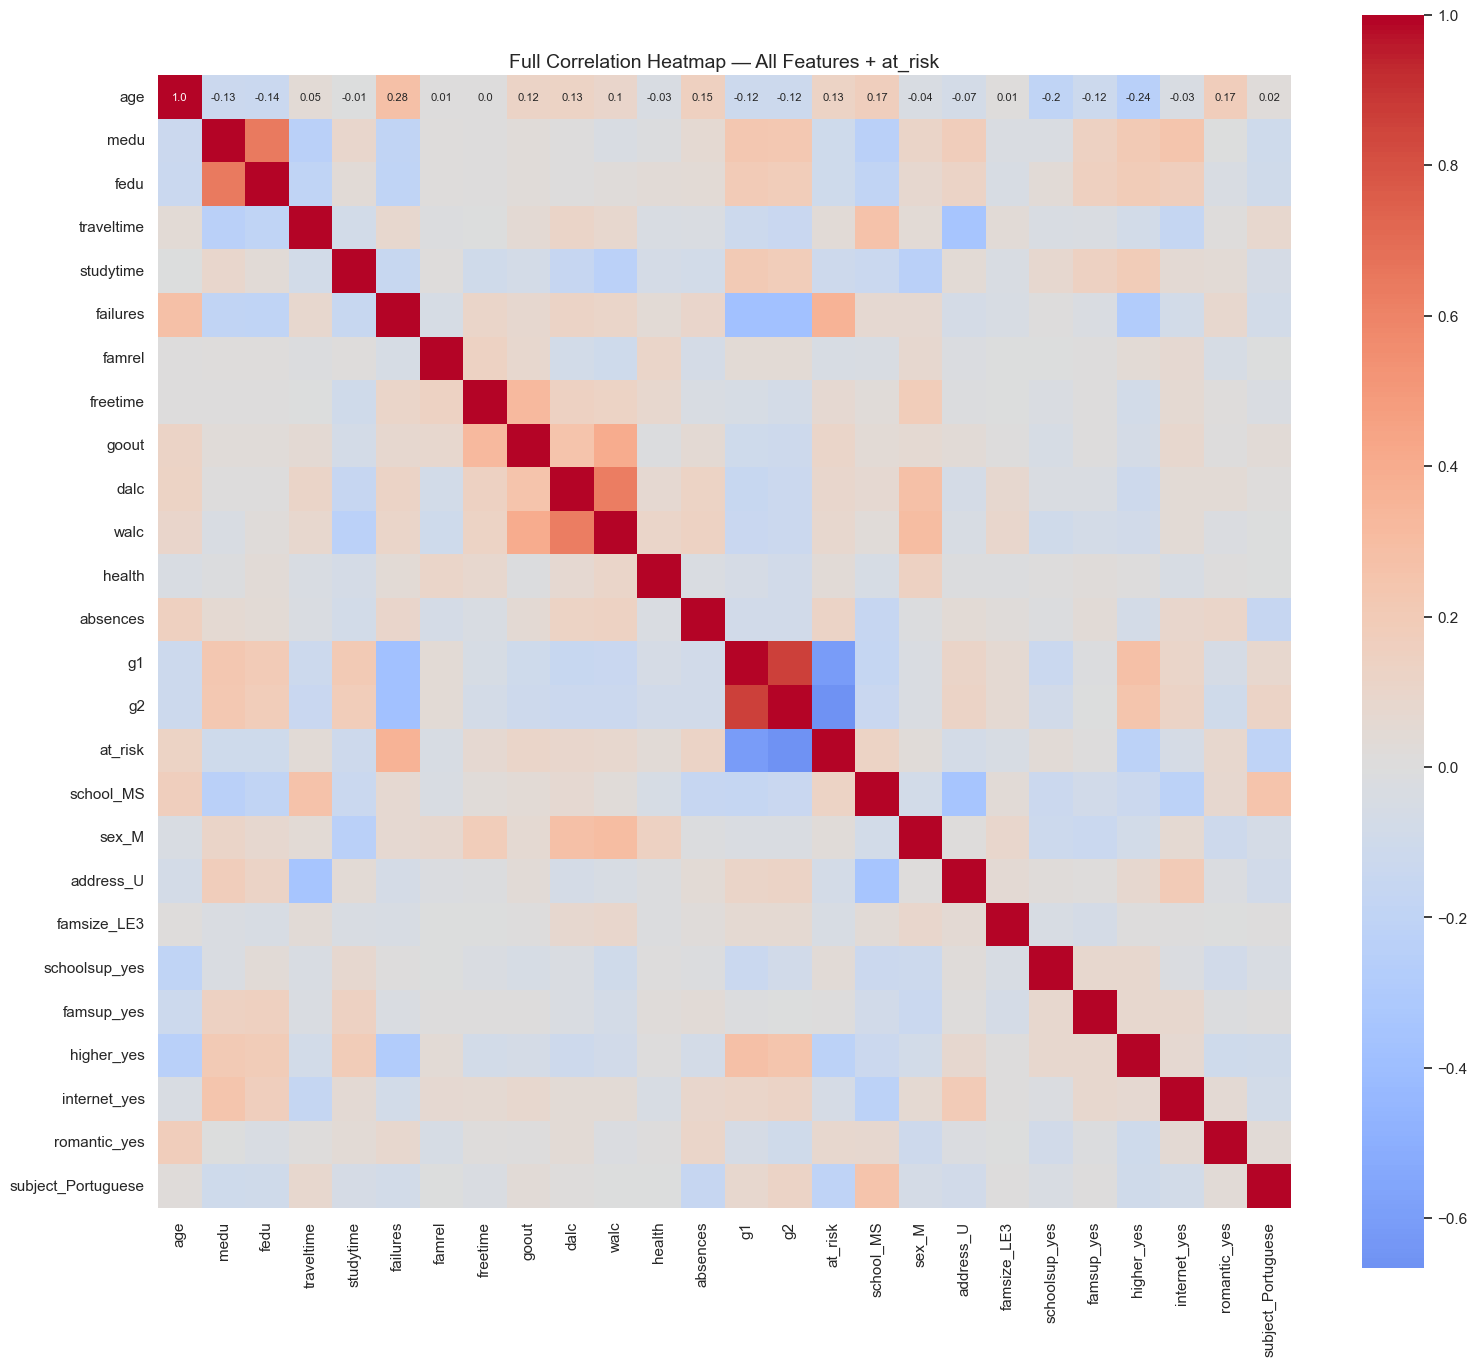

In [9]:
# Calculate correlation matrix
full_corr = df_features.corr(numeric_only=True)

# Round values to 2 decimal places
corr_values = full_corr.round(2)


# Create heatmap
fig, ax = plt.subplots(figsize=(16, 14))

sns.heatmap(
    full_corr,
    cmap="coolwarm",
    center=0,
    annot=corr_values,          # Explicitly provide values to display
    fmt="",                     # Values are already rounded
    square=True,
    ax=ax,
    annot_kws={"size": 8}       # Control annotation text size
)

ax.set_title(
    "Full Correlation Heatmap — All Features + at_risk",
    fontsize=14
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

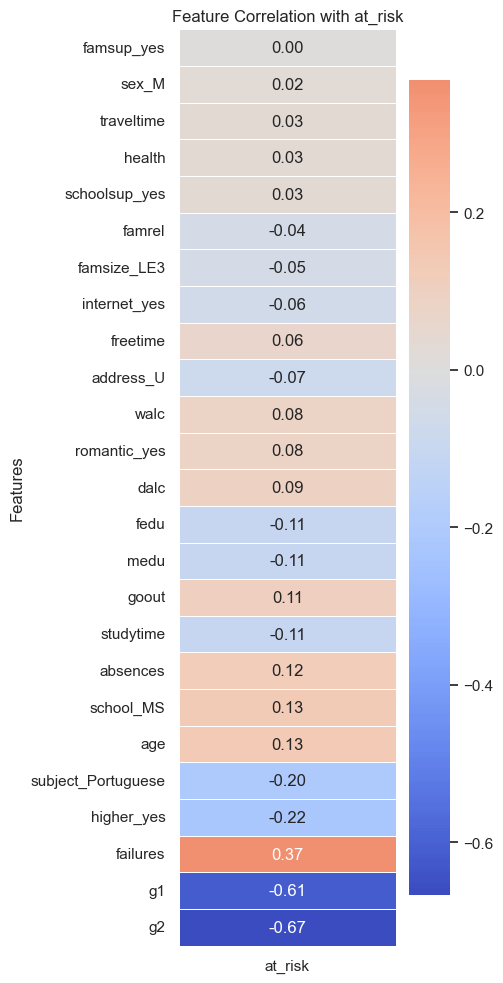

In [10]:
# Correlation of each feature with at_risk
target_corr = (
    df_features
    .corr(numeric_only=True)["at_risk"]
    .drop("at_risk")
)

# Sort features by correlation strength
target_corr = target_corr.reindex(
    target_corr.abs().sort_values().index
)


# Create single-column heatmap
fig, ax = plt.subplots(figsize=(5, 10))

sns.heatmap(
    target_corr.to_frame("at_risk"),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    ax=ax
)

ax.set_title("Feature Correlation with at_risk")
ax.set_xlabel("")
ax.set_ylabel("Features")

plt.tight_layout()
plt.show()

## 1. Feature Correlation with `at_risk`

- **G2** has the strongest negative correlation with `at_risk` (**-0.67**), indicating that students with higher second-period grades are much less likely to be at risk.
- **G1** also has a strong negative correlation (**-0.61**), showing that earlier academic performance is strongly associated with student risk.
- **Failures** has the strongest positive correlation (**+0.37**), indicating that students with more previous failures tend to have higher risk.
- **Higher education intention (`higher_yes`)** has a moderate negative correlation (**-0.22**), suggesting that students planning to pursue higher education tend to have lower risk.
- **Subject_Portuguese** has a negative correlation (**-0.20**), indicating a somewhat lower risk compared with Mathematics.
- **Age, school_MS, and absences** have small positive correlations (**around +0.12 to +0.13**).
- Most remaining demographic and social features have **weak correlations close to zero**.

### Conclusion

Previous academic performance, especially **G1 and G2**, is the strongest factor associated with student risk. Previous failures also provide meaningful risk information. However, correlation only measures linear relationships and does not imply causation.

---

#### 3. Target leakage check plot

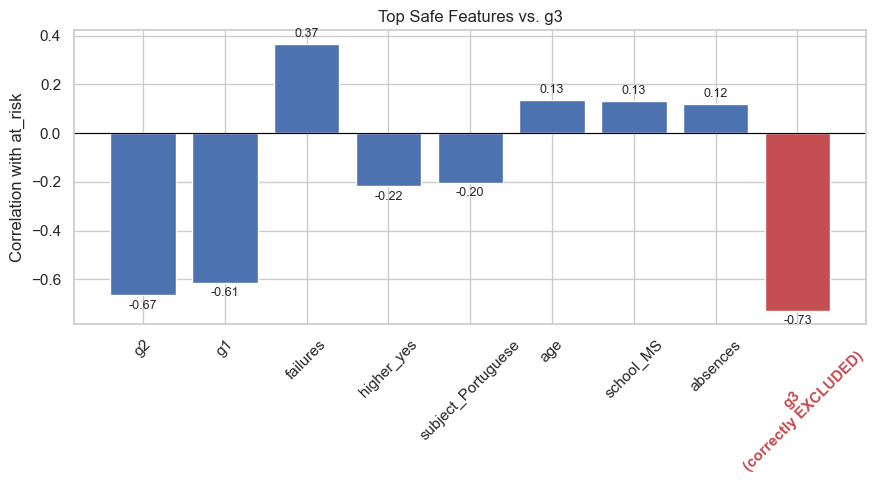

g3's correlation with at_risk, if it HAD been left in: -0.730
Is g3 actually in df_features? False
Confirmed: g3 is excluded from the saved feature matrix.


In [11]:
# Reload g3 only for the leakage diagnostic
leakage_check = (
    df_features
    .corr(numeric_only=True)["at_risk"]
    .drop("at_risk")
)

# Calculate g3 correlation separately
g3_corr_if_present = (
    df["g3"].astype(float)
    .corr(df["at_risk"].astype(float))
)


# Select top 8 safe features
top_safe = (
    leakage_check
    .dropna()
    .reindex(leakage_check.dropna().abs().sort_values(ascending=False).index)
    .head(8)
)


# Prepare bar chart data
bars = list(top_safe.index) + ["g3\n(correctly EXCLUDED)"]
values = list(top_safe.values) + [g3_corr_if_present]

bar_colors = ["#4C72B0"] * len(top_safe) + ["#C44E52"]


# Create chart
fig, ax = plt.subplots(figsize=(9, 5))

bar_container = ax.bar(
    bars,
    values,
    color=bar_colors
)


# Add correlation values on top of bars
ax.bar_label(
    bar_container,
    labels=[f"{value:.2f}" for value in values],
    padding=3,
    fontsize=9
)


# Reference line
ax.axhline(0, color="black", linewidth=0.8)

# Chart labels
ax.set_title("Top Safe Features vs. g3")
ax.set_ylabel("Correlation with at_risk")
ax.tick_params(axis="x", rotation=45)


# Highlight g3 label
for label in ax.get_xticklabels():
    if "g3" in label.get_text():
        label.set_color("#C44E52")
        label.set_fontweight("bold")


plt.tight_layout()
plt.show()


# Leakage verification
print(
    f"g3's correlation with at_risk, if it HAD been left in: "
    f"{g3_corr_if_present:.3f}"
)

print(f"Is g3 actually in df_features? {'g3' in df_features.columns}")

assert "g3" not in df_features.columns, \
    "LEAKAGE: g3 must not be in the feature matrix"

print("Confirmed: g3 is excluded from the saved feature matrix.")

**Reading this:** `g3`'s correlation with `at_risk` is deliberately shown here
in red, off to the side, and labeled "correctly EXCLUDED" — it would almost
certainly be the single strongest bar on this chart (since `at_risk` is
literally derived from it), which is exactly why it can't be a feature. This
plot exists purely as a visual safety check, not as an input to modeling — the
`assert` statement below it is the actual guardrail; the chart just makes it
easy to *see* what leakage would look like if this check were ever accidentally
removed.

#### Target distribution — class balance

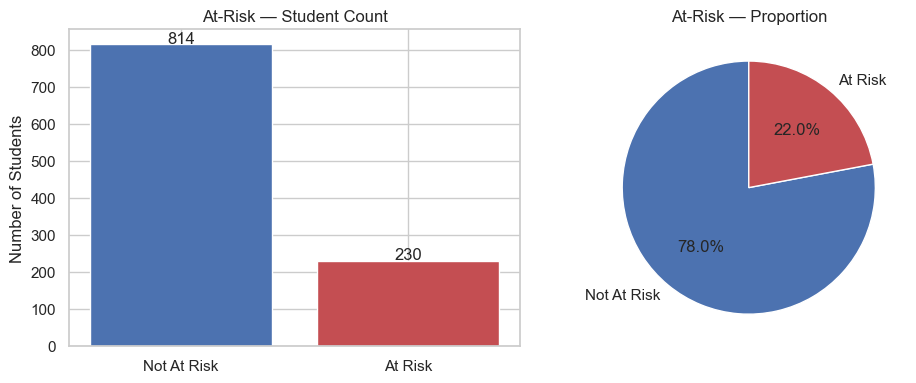

At-Risk Rate: 22.0% (230 of 1044 students)


In [19]:
# 8. At-Risk Class Distribution

# Count and percentage of each class
counts = df_features["at_risk"].value_counts().sort_index()
rates = df_features["at_risk"].value_counts(normalize=True).sort_index()


# Same colors used throughout the analysis
colors = ["#4C72B0", "#C44E52"]


# Create two plots
fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4)
)


# Bar chart — Student counts
axes[0].bar(
    ["Not At Risk", "At Risk"],
    counts.values,
    color=colors
)

axes[0].set_title("At-Risk — Student Count")
axes[0].set_ylabel("Number of Students")

# Add values on top of bars
for i, value in enumerate(counts.values):
    axes[0].text(
        i,
        value + 5,
        str(value),
        ha="center"
    )


# Pie chart — Class proportion
axes[1].pie(
    rates.values,
    labels=["Not At Risk", "At Risk"],
    autopct="%1.1f%%",
    colors=colors,
    startangle=90
)

axes[1].set_title("At-Risk — Proportion")


plt.tight_layout()
plt.show()


# Display overall at-risk rate
print(
    f"At-Risk Rate: {rates[1]:.1%} "
    f"({counts[1]} of {counts.sum()} students)"
)

**Why this matters for reading every chart above:** roughly a 22%/78% split —
every correlation, boxplot, and category-rate chart in this section should be
read against that baseline. A category whose `at_risk` rate sits well above
~22% is genuinely higher-risk; one sitting right around ~22% is behaving like
the population average, not showing a real effect.

### 7. Summary — target, features, and what changed vs. `feature_engineering.py`

**Target:** `at_risk` is **not present in the raw data** — it's derived here as
`G3 < 10` (0-20 scale, 10 = pass mark). This is a binary classification target,
computed once in Section 2 and never touched again downstream.

**Features:** `g1`, `g2`, plus one-hot encoded demographic/social columns
(`school`, `sex`, `address`, `famsize`, `schoolsup`, `famsup`, `higher`,
`internet`, `romantic`, `subject`). 30ish columns after encoding.

**Optimizations made relative to the original `build_uci_feature_matrix(conn)`:**
1. **Added `subject` as a feature** (Mathematics vs. Portuguese) — the original
   function silently discarded this distinction even though the Day 3 EDA notebook
   found materially different `at_risk` rates and grade distributions by subject.
2. **Explicit leakage assertion** (`assert "g3" not in df_features.columns`) —
   the original code just drops the column and trusts it; this notebook fails loudly
   instead of silently if that ever regresses.
3. **Explicit dtype-safety net** (`select_dtypes(include=["number","bool"])` with a
   printed warning) — same end behavior as the original, but now visible instead of
   silent, in case a future raw-column addition isn't numeric or dummy-encoded yet.
4. **Persisted to `data/processed/uci_feature_matrix.csv`** — the original function
   returns an in-memory DataFrame only; this notebook saves it so the modeling
   notebook (and `model_baseline.py`) doesn't need a live MySQL connection to reuse it.

This feature matrix is the direct input to `model_baseline.split_train_test()` and
`model_baseline.train_baseline_model()` in the next notebook.

**Visualizations added in Section 6b:** correlation-with-target bar chart, full feature correlation heatmap, a dedicated target-leakage check plot proving `g3` stays excluded, boxplots of `g1`/`g2`/`absences`/`failures` by `at_risk`, risk rate by encoded category, and the target class-balance chart — together these give a direct visual explanation of which variables are driving risk, not just the printed top-10 list from Section 5.